In [1]:
pip install langgraph -q

# Простейший граф

In [10]:
from typing import TypedDict
from datetime import date

class UserState(TypedDict):
    name: str
    surname: str
    age: int
    birth_date: date

from langgraph.graph import StateGraph

graph = StateGraph(UserState)

In [11]:
dir(graph)

['__annotations__',
 '__class__',
 '__class_getitem__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__orig_bases__',
 '__parameters__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_schema',
 '_all_edges',
 '_node_defaults',
 'add_conditional_edges',
 'add_edge',
 'add_node',
 'add_sequence',
 'branches',
 'channels',
 'compile',
 'compiled',
 'context_schema',
 'edges',
 'input_schema',
 'managed',
 'nodes',
 'output_schema',
 'schemas',
 'set_conditional_entry_point',
 'set_entry_point',
 'set_finish_point',
 'set_node_defaults',
 'state_schema',
 'validate',
 'waiting_edges']

In [13]:
# У графа должны быть начальная и конечная вершины
 graph.compile()

ValueError: Graph must have an entrypoint: add at least one edge from START to another node

In [14]:
from langgraph.graph import StateGraph, START, END

In [15]:
# Основа: Вычисляет точный возраст человека от сегодняшней даты.

def calculate_age(state: UserState) -> UserState:
    today = date.today()
    age = today.year - state["birth_date"].year
    if (today.month, today.day) < (state["birth_date"].month, state["birth_date"].day):
        age -= 1
    state["age"] = age
    return state

In [16]:
graph.add_node("calculate_age", calculate_age)

In [17]:
graph.add_edge(START, END)

# добавим к нему введенный выше узел
graph.add_edge(START, "calculate_age")
graph.add_edge("calculate_age", END)

In [19]:
app = graph.compile()
result = app.invoke({"name": "Алексей",
                     "surname": "Яковенко",
                     "birth_date": date.fromisoformat("1993-02-19")})
print(result)
#{'name': 'Алексей', 'surname': 'Яковенко', 'age': 32, 'birth_date': datetime.date(1993, 2, 19)}

{'name': 'Алексей', 'surname': 'Яковенко', 'age': 33, 'birth_date': datetime.date(1993, 2, 19)}


In [20]:
def gen_png_graph(app_obj, name_photo: str = "graph.png") -> None:
    """
    Генерирует PNG-изображение графа и сохраняет его в файл.

    Args:
        app_obj: Скомпилированный объект графа
        name_photo: Имя файла для сохранения (по умолчанию "graph.png")
    """
    with open(name_photo, "wb") as f:
        f.write(app_obj.get_graph().draw_mermaid_png())

app = graph.compile()
gen_png_graph(app, name_photo="graph_example_4.png")


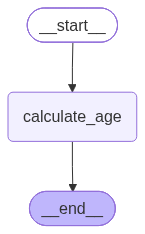

In [27]:
# или же просто можно вызвать скомпилированный граф

app

# Условия и циклы

In [36]:
if graph:
  del graph

## Условия

In [33]:
from typing import TypedDict
from datetime import date
from langgraph.graph import StateGraph

class UserState(TypedDict):
    name: str
    surname: str
    age: int
    birth_date: date
    message: str  # Новое поле для хранения сообщения пользователю

def check_drive(state: UserState) -> str:
    if state["age"] >= 18:
        return "можно"
    else:
        return "нельзя"

# Создание узлов с результатом

def generate_success_message(state: UserState) -> dict:
    return {
        "message": f"Поздравляем, {state['name']} {state['surname']}! "
                   f"Вам уже {state['age']} лет и вы можете водить!"
    }

def generate_failure_message(state: UserState) -> dict:
    return {
        "message": f"К сожалению, {state['name']} {state['surname']}, "
                   f"вам ещё только {state['age']} лет и вы не можете водить."
    }

graph = StateGraph(UserState)

# узлы

graph.add_node("calculate_age", calculate_age)
graph.add_node("generate_success_message", generate_success_message)
graph.add_node("generate_failure_message", generate_failure_message)

# ребра
graph.add_edge(START, "calculate_age")

graph.add_conditional_edges(
    "calculate_age",
    check_drive,  # Словарь маршрутизации
    {
        "можно": "generate_success_message",
        "нельзя": "generate_failure_message"
    }
)
# Мы тут задействовали новый метод — add_conditional_edges. Данный метод:
#     Первым аргументом принимает название узла, с которого начинается условная логика
#     Вторым аргументом принимает функцию условия (не строку с названием, а саму функцию!)
#     Третьим аргументом принимает словарь маршрутизации

graph.add_edge("generate_success_message", END)
graph.add_edge("generate_failure_message", END)

# Запуск

app = graph.compile()
result = app.invoke({
    "name": "Алексей",
    "surname": "Яковенко",
    "birth_date": date.fromisoformat("1993-02-19")
})

print(result)

# {
#     'name': 'Алексей',
#     'surname': 'Яковенко',
#     'age': 32,
#     'birth_date': datetime.date(1993, 2, 19),
#     'message': 'Поздравляем, Алексей Яковенко! Вам уже 32 лет и вы можете водить!'
# }

{'name': 'Алексей', 'surname': 'Яковенко', 'age': 33, 'birth_date': datetime.date(1993, 2, 19), 'message': 'Поздравляем, Алексей Яковенко! Вам уже 33 лет и вы можете водить!'}


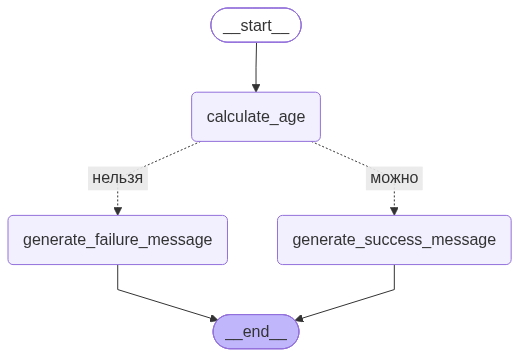

In [34]:
app

## Циклы

In [44]:
# Toy example: специальный узел, который будет при каждом к нему обращении увеличивать сегодняшнюю дату на 1 день

from typing import TypedDict
from datetime import date, timedelta


class UserState(TypedDict):
    name: str
    surname: str
    age: int
    birth_date: date
    today: date  # Новое поле для хранения "текущей" даты
    message: str

def calculate_age(state: UserState) -> dict:
    """
    Вычисляет точный возраст человека от переданной даты.
    """
    today = state["today"]  # Берём дату из состояния, а не системную
    # Вычисляем разность в годах
    age = today.year - state["birth_date"].year
    # Проверяем, прошёл ли уже день рождения в этом году
    if (today.month, today.day) < (state["birth_date"].month, state["birth_date"].day):
        age -= 1
    return {"age": age}

def autoincrement_date(state: UserState) -> dict:
    """
    Увеличивает текущую дату на один день.
    """
    current_date = state["today"]
    new_date = current_date + timedelta(days=1)
    print(f"{current_date} -> {new_date}")  # Для наглядности процесса
    return {"today": new_date}

def generate_success_message(state: UserState) -> dict:
    return {
        "message": f"Поздравляем, {state['name']} {state['surname']}! "
                   f"Вам уже {state['age']} лет и вы можете водить!"
    }

# Построение графа
graph = StateGraph(UserState)
graph.add_node("autoincrement_date", autoincrement_date)
graph.add_node("calculate_age", calculate_age)
graph.add_node("generate_success_message", generate_success_message)

graph.add_edge(START, "calculate_age")
graph.add_conditional_edges(
    "calculate_age",
    check_drive,
    {
        "можно": "generate_success_message",
        "нельзя": "autoincrement_date"
    }
)
graph.add_edge("generate_success_message", END)
graph.add_edge("autoincrement_date", "calculate_age")

# Запуск графа

app = graph.compile()
result = app.invoke({
    "name": "Алексей",
    "surname": "Яковенко",
    "birth_date": date.fromisoformat("2009-02-19"),  # Несовершеннолетний
    "today": date.today()
}, {"recursion_limit": 1000})
print(result)

2026-11-08 -> 2026-11-09
2026-11-09 -> 2026-11-10
2026-11-10 -> 2026-11-11
2026-11-11 -> 2026-11-12
2026-11-12 -> 2026-11-13
2026-11-13 -> 2026-11-14
2026-11-14 -> 2026-11-15
2026-11-15 -> 2026-11-16
2026-11-16 -> 2026-11-17
2026-11-17 -> 2026-11-18
2026-11-18 -> 2026-11-19
2026-11-19 -> 2026-11-20
2026-11-20 -> 2026-11-21
2026-11-21 -> 2026-11-22
2026-11-22 -> 2026-11-23
2026-11-23 -> 2026-11-24
2026-11-24 -> 2026-11-25
2026-11-25 -> 2026-11-26
2026-11-26 -> 2026-11-27
2026-11-27 -> 2026-11-28
2026-11-28 -> 2026-11-29
2026-11-29 -> 2026-11-30
2026-11-30 -> 2026-12-01
2026-12-01 -> 2026-12-02
2026-12-02 -> 2026-12-03
2026-12-03 -> 2026-12-04
2026-12-04 -> 2026-12-05
2026-12-05 -> 2026-12-06
2026-12-06 -> 2026-12-07
2026-12-07 -> 2026-12-08
2026-12-08 -> 2026-12-09
2026-12-09 -> 2026-12-10
2026-12-10 -> 2026-12-11
2026-12-11 -> 2026-12-12
2026-12-12 -> 2026-12-13
2026-12-13 -> 2026-12-14
2026-12-14 -> 2026-12-15
2026-12-15 -> 2026-12-16
2026-12-16 -> 2026-12-17
2026-12-17 -> 2026-12-18


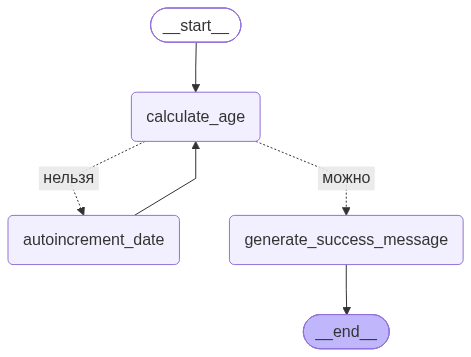

In [45]:
app

In [46]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class UserState(TypedDict):
    age: int
    message: str


def check_age(state: UserState) -> str:
    """Условная функция для проверки возраста"""
    return "совершеннолетний" if state["age"] >= 18 else "не_совершеннолетний"


def generate_success_message(state: UserState) -> dict:
    """Генерирует сообщение для совершеннолетних"""
    return {"message": f"Вам уже {state['age']} лет и вы можете водить!"}


def generate_failure_message(state: UserState) -> dict:
    """Генерирует сообщение для несовершеннолетних"""
    return {"message": f"Вам ещё только {state['age']} лет и вы не можете водить."}

graph = StateGraph(UserState)

# Узлы
# Фиктивный узел - просто передаёт состояние дальше
graph.add_node("fake_node", lambda state: state)

# Основные узлы обработки
graph.add_node("generate_success_message", generate_success_message)
graph.add_node("generate_failure_message", generate_failure_message)

# Ребра
# Связываем START с фиктивным узлом
graph.add_edge(START, "fake_node")

# От фиктивного узла идёт условное ребро
graph.add_conditional_edges(
    "fake_node",
    check_age,
    {
        "совершеннолетний": "generate_success_message",
        "не_совершеннолетний": "generate_failure_message"
    }
)

# Завершаем оба пути
graph.add_edge("generate_success_message", END)
graph.add_edge("generate_failure_message", END)

# Запуск
app = graph.compile()

# Тест для несовершеннолетнего
result_minor = app.invoke({"age": 17})
print("Результат для 17 лет:", result_minor)

# Тест для совершеннолетнего
result_adult = app.invoke({"age": 25})
print("Результат для 25 лет:", result_adult)

Результат для 17 лет: {'age': 17, 'message': 'Вам ещё только 17 лет и вы не можете водить.'}
Результат для 25 лет: {'age': 25, 'message': 'Вам уже 25 лет и вы можете водить!'}


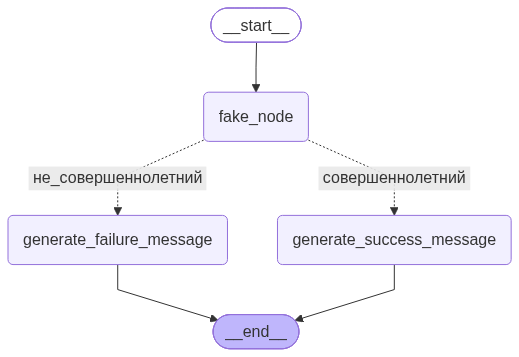

In [47]:
app

# Подключаем LLM

In [4]:
pip install langchain_huggingface -q

In [5]:
def build_qwen_huggingface():
    """Лёгкий локальный Qwen для проверки llm.invoke в Colab."""
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from langchain_huggingface import ChatHuggingFace, HuggingFacePipeline

    model_id = "Qwen/Qwen2.5-0.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    model_kwargs = {"torch_dtype": "auto"}
    if torch.cuda.is_available():
        model_kwargs["device_map"] = "auto"

    model = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)
    if not torch.cuda.is_available():
        model = model.to("cpu")

    from transformers import pipeline

    text_generation = pipeline(
        "text-generation",
        model=model,
        tokenizer=tokenizer,
        max_new_tokens=5000,
        do_sample=False,
        return_full_text=False,
    )
    base_llm = HuggingFacePipeline(pipeline=text_generation)
    return ChatHuggingFace(llm=base_llm)

llm = build_qwen_huggingface()
llm.invoke("Кто тебя создал?")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

AIMessage(content='Я создавался в рамках проекта Alibaba Cloud, который предоставляет разработчику искусственного интеллекта и машинного обучения. Я был создан для решения задач, связанных с обучением и предсказанием, а также для создания различных систем и моделей.', additional_kwargs={}, response_metadata={}, id='lc_run--01a1a670-d8b8-7154-a1ab-f6e895bbc9a8-0', tool_calls=[], invalid_tool_calls=[])

In [6]:
llm.invoke("Кто твой папочка?")

AIMessage(content='Я не являюсь родителем или близким родственником, поэтому у меня нет папы или мамы. Я искусственный интеллект созданный компанией Alibaba Cloud, и я не имею личных отношений с anyone.', additional_kwargs={}, response_metadata={}, id='lc_run--01a1a671-4ad7-71c7-b520-57c4f00a273f-0', tool_calls=[], invalid_tool_calls=[])